# Формы: hf-tRNS, TES77, синус (tACS)

Левый (или единственный) канал wav из `presets/`, плюс один период синуса вместо tACS.
Ось Y нормирована так, что **пик по модулю = 1 = амплитуда в меню**.
Стрелки: амплитуда (от нуля до пика) и размах (от минимума до максимума); на TES77 ещё действующее значение (RMS).

In [6]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

PRESETS = Path("../presets")
OUT_PNG = Path("preset_waveforms.png")
POST_PNG = Path("/home/sk/Documents/Obsidian Vault/boosty/e-kolkhoz/Расходники и Пресетошная/preset_waveforms.png")

In [7]:
def left_norm(path: Path):
    sr, x = wavfile.read(path)
    x = np.asarray(x, dtype=float)
    if x.ndim == 2:
        x = x[:, 0]
    peak = np.max(np.abs(x))
    y = x / peak
    t_ms = np.arange(len(y)) / sr * 1000.0
    rms = float(np.sqrt(np.mean(y**2)))
    return t_ms, y, sr, rms


def vspan(ax, x, y0, y1, text, color, dx_frac=0.018):
    """Вертикальная двусторонняя стрелка + подпись справа от неё."""
    ax.annotate(
        "",
        xy=(x, y1),
        xytext=(x, y0),
        arrowprops=dict(arrowstyle="<->", color=color, lw=1.6,
                        mutation_scale=14, shrinkA=0, shrinkB=0),
        annotation_clip=False,
    )
    x1, x2 = ax.get_xlim()
    ax.text(
        x + dx_frac * (x2 - x1),
        0.5 * (y0 + y1),
        text,
        color=color,
        va="center",
        ha="left",
        fontsize=8.5,
        clip_on=False,
    )


t_hf, y_hf, sr_hf, rms_hf = left_norm(PRESETS / "hf-tRNS.wav")
t_tes, y_tes, sr_tes, rms_tes = left_norm(PRESETS / "tes-77hz.wav")

n_sin = 400
t_sin = np.linspace(0, 1, n_sin, endpoint=False) * 1000.0 / 140.0
y_sin = np.sin(2 * np.pi * np.arange(n_sin) / n_sin)

win_ms = 80.0
n_win = int(sr_hf * win_ms / 1000.0)
i_peak = int(np.argmax(np.abs(y_hf)))
i0 = max(0, i_peak - n_win // 2)
i1 = min(len(y_hf), i0 + n_win)
i0 = max(0, i1 - n_win)
t_hf_w = t_hf[i0:i1] - t_hf[i0]
y_hf_w = y_hf[i0:i1]

print(f"hf-tRNS: rms={rms_hf:.3f} ymin={y_hf.min():.3f} ymax={y_hf.max():.3f}")
print(f"TES77:   rms={rms_tes:.3f} ymin={y_tes.min():.3f} ymax={y_tes.max():.3f}")

hf-tRNS: rms=0.243 ymin=-1.000 ymax=0.921
TES77:   rms=0.640 ymin=-0.410 ymax=1.000


saved /home/sk/Yandex.Disk/Obsidian Vault/tPRNS/tRNS/py_experiments/preset_waveforms.png
saved /home/sk/Documents/Obsidian Vault/boosty/e-kolkhoz/Расходники и Пресетошная/preset_waveforms.png


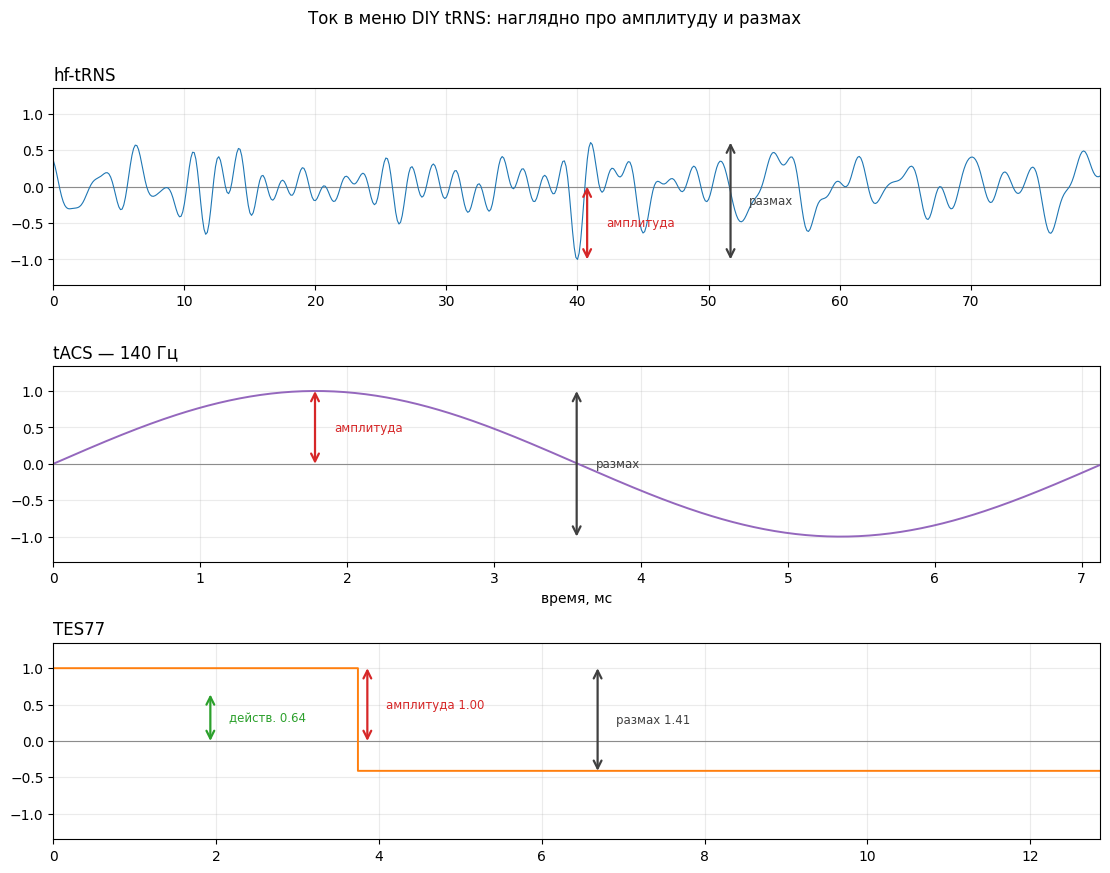

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(11.2, 8.6), sharey=True)

def style(ax, title):
    ax.set_title(title, loc="left")
    ax.axhline(0, color="0.55", lw=0.8)
    ax.set_ylim(-1.35, 1.35)
    ax.grid(True, alpha=0.25)

# --- hf-tRNS ---
style(axes[0], "hf-tRNS")
axes[0].plot(t_hf_w, y_hf_w, color="C0", lw=0.8)
axes[0].set_xlim(0, t_hf_w[-1])
x_hf = t_hf_w[-1] * 0.51
amp_hf = float(np.max(np.abs(y_hf_w)))
sign_hf = 1.0 if abs(y_hf_w.max()) >= abs(y_hf_w.min()) else -1.0
vspan(axes[0], x_hf, 0, sign_hf * amp_hf, "амплитуда", "C3")
vspan(axes[0], x_hf + t_hf_w[-1] * 0.137, y_hf_w.min(), y_hf_w.max(), "размах", "0.25")

# --- tACS синус ---
style(axes[1], "tACS — 140 Гц")
axes[1].plot(t_sin, y_sin, color="C4", lw=1.4)
smax = t_sin[-1]
axes[1].set_xlim(0, smax)
vspan(axes[1], smax * 0.25, 0, 1.0, "амплитуда", "C3")
vspan(axes[1], smax * 0.5, -1.0, 1.0, "размах", "0.25")
axes[1].set_xlabel("время, мс")

# --- TES77 ---
style(axes[2], "TES77")
axes[2].plot(t_tes, y_tes, color="C1", lw=1.4, drawstyle="steps-post")
tmax = t_tes[-1]
pp_tes = float(y_tes.max() - y_tes.min())
axes[2].set_xlim(0, tmax)
vspan(axes[2], tmax * 0.3, 0, y_tes.max(), f"амплитуда {y_tes.max():.2f}", "C3")
vspan(axes[2], tmax * 0.52, y_tes.min(), y_tes.max(), f"размах {pp_tes:.2f}", "0.25")
vspan(axes[2], tmax * 0.15, 0, rms_tes, f"действ. {rms_tes:.2f}", "C2")



fig.suptitle("Ток в меню DIY tRNS: наглядно про амплитуду и размах", y=1.01)
fig.tight_layout()
fig.savefig(OUT_PNG, dpi=140, bbox_inches="tight")
POST_PNG.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(POST_PNG, dpi=140, bbox_inches="tight")
print("saved", OUT_PNG.resolve())
print("saved", POST_PNG)
plt.show()